# SAM-Assisted Relabeling (Alternative: 500-image subset with train/val split)

This notebook uses SAM 2 automatic mask generation to create high-quality segmentation masks for a **subset** of your aerial images.

**Strategy**:
1. Sample 500 images from the original train split
2. Run SAM automatic mask generation on the sampled images
3. Assign class labels by matching masks to existing YOLO bounding boxes (IoU-based)
4. Split into train (400) / val (100) for finetuning
5. Export as a new YOLO-format dataset

**Output**: `data/sam_labels/` with train/val splits (80/20), test points to original labels.


In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import cv2
import matplotlib.pyplot as plt
import numpy as np
import random
import yaml
from tqdm import tqdm
from sam2.automatic_mask_generator import SAM2AutomaticMaskGenerator
from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor

from helpers.ntbk_utils import load_data_yaml, load_yolo_labels, compute_iou

plt.rcParams['figure.figsize'] = (12, 8)


In [2]:
# Configuration
DATA_DIR = Path("../aerial_images")
OUTPUT_DIR = Path("../data/sam_labels")
YAML_PATH = DATA_DIR / "data.yaml"

# SAM 2 config - pick model size (base_plus is default)
SAM_MODELS = {
    "tiny":      ("sam2.1_hiera_tiny.pt",      "configs/sam2.1/sam2.1_hiera_t.yaml"),
    "small":     ("sam2.1_hiera_small.pt",     "configs/sam2.1/sam2.1_hiera_s.yaml"),
    "base_plus": ("sam2.1_hiera_base_plus.pt", "configs/sam2.1/sam2.1_hiera_b+.yaml"),
    "large":     ("sam2.1_hiera_large.pt",     "configs/sam2.1/sam2.1_hiera_l.yaml"),
}
SAM_SIZE = "base_plus"  # <- pick: tiny, small, base_plus, large
SAM_CHECKPOINT, MODEL_CONFIG = SAM_MODELS[SAM_SIZE]

# Sampling and split config
MAX_TRAIN_IMAGES = 500   # label only this many train images
VAL_FRACTION = 0.2       # 80/20 split: 400 train / 100 val
SEED = 42                # reproducible sampling

# Mask-to-class matching
IOU_THRESHOLD = 0.3  # Minimum IoU to assign class to mask
MIN_MASK_AREA = 100  # Filter out tiny masks

data_cfg = load_data_yaml(YAML_PATH)
CLASS_NAMES = data_cfg["names"]
print(f"Dataset classes: {CLASS_NAMES}")
print(f"Output directory: {OUTPUT_DIR}")
print(f"Will sample {MAX_TRAIN_IMAGES} images, split {1-VAL_FRACTION:.0%}/{VAL_FRACTION:.0%} train/val")


Dataset classes: ['PMT', 'articulated-bus', 'bus', 'car', 'freight', 'motorbike', 'small bus', 'truck']
Output directory: ../data/sam_labels
Will sample 500 images, split 80%/20% train/val


In [3]:
# Download SAM 2 checkpoint if not present
import urllib.request

CHECKPOINT_URLS = {
    "sam2.1_hiera_tiny.pt":      "https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_tiny.pt",
    "sam2.1_hiera_small.pt":     "https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_small.pt",
    "sam2.1_hiera_base_plus.pt": "https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_base_plus.pt",
    "sam2.1_hiera_large.pt":     "https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_large.pt",
}

ckpt_path = Path(SAM_CHECKPOINT)
if not ckpt_path.exists():
    url = CHECKPOINT_URLS[SAM_CHECKPOINT]
    print(f"Downloading {SAM_CHECKPOINT}...")
    urllib.request.urlretrieve(url, ckpt_path)
    print(f"Downloaded to {ckpt_path}")
else:
    print(f"Checkpoint already exists: {ckpt_path}")


Checkpoint already exists: sam2.1_hiera_base_plus.pt


In [4]:
# Initialize SAM 2
print("Loading SAM 2 model...")
sam2_model = build_sam2(MODEL_CONFIG, SAM_CHECKPOINT, device="cpu")  # Use "cuda" if available
mask_generator = SAM2AutomaticMaskGenerator(sam2_model)
print("SAM 2 loaded successfully")


Loading SAM 2 model...
SAM 2 loaded successfully


/Users/benedict/miniconda3/envs/yolo/lib/python3.11/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [5]:
# Sample images and create train/val split
all_train_images = sorted((DATA_DIR / "train" / "images").glob("*.jpg"))
print(f"Total train images available: {len(all_train_images)}")

random.seed(SEED)
sampled_images = random.sample(all_train_images, min(MAX_TRAIN_IMAGES, len(all_train_images)))
print(f"Sampled {len(sampled_images)} images")

random.shuffle(sampled_images)
split_idx = int(len(sampled_images) * (1 - VAL_FRACTION))
train_images = sampled_images[:split_idx]
val_images = sampled_images[split_idx:]

print(f"Train split: {len(train_images)} images")
print(f"Val split: {len(val_images)} images")


Total train images available: 1710
Sampled 500 images
Train split: 400 images
Val split: 100 images


In [6]:
# Setup output directories
for split in ["train", "valid"]:
    (OUTPUT_DIR / split / "images").mkdir(parents=True, exist_ok=True)
    (OUTPUT_DIR / split / "labels").mkdir(parents=True, exist_ok=True)

# Copy data.yaml with updated paths (test points to original)
output_yaml = OUTPUT_DIR / "data.yaml"
with open(output_yaml, "w") as f:
    yaml.dump({
        "train": "train/images",
        "val": "valid/images",
        "test": "../aerial_images/test/images",
        "nc": len(CLASS_NAMES),
        "names": CLASS_NAMES,
    }, f)
print(f"Created {output_yaml}")


Created ../data/sam_labels/data.yaml


In [7]:
def mask_to_polygon(mask: np.ndarray) -> list[list[float]]:
    """Convert binary mask to polygon points (normalized)."""
    mask_uint8 = (mask * 255).astype(np.uint8)
    contours, _ = cv2.findContours(mask_uint8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    polygons = []
    h, w = mask.shape
    for contour in contours:
        if len(contour) < 3:
            continue
        contour = contour.squeeze()
        if len(contour.shape) == 1:
            continue
        polygon = contour[:, :2].astype(float)
        polygon[:, 0] /= w
        polygon[:, 1] /= h
        polygons.append(polygon.flatten().tolist())
    return polygons


def mask_to_bbox(mask: np.ndarray) -> list[float]:
    """Convert binary mask to bounding box [x_center, y_center, width, height] normalized."""
    y_coords, x_coords = np.where(mask)
    if len(x_coords) == 0:
        return []
    x_min, x_max = x_coords.min(), x_coords.max()
    y_min, y_max = y_coords.min(), y_coords.max()
    h, w = mask.shape
    x_center = ((x_min + x_max) / 2) / w
    y_center = ((y_min + y_max) / 2) / h
    width = (x_max - x_min) / w
    height = (y_max - y_min) / h
    return [x_center, y_center, width, height]


def assign_class_to_mask(mask: np.ndarray, gt_boxes: list, iou_threshold: float) -> int:
    """Assign class to mask by best IoU match with GT boxes."""
    y_coords, x_coords = np.where(mask)
    if len(x_coords) == 0:
        return -1
    
    mask_bbox = [x_coords.min(), y_coords.min(), x_coords.max(), y_coords.max()]
    
    best_cls = -1
    best_iou = 0.0
    for gt in gt_boxes:
        gt_bbox = gt["bbox"]
        iou = compute_iou(mask_bbox, gt_bbox)
        if iou > best_iou:
            best_iou = iou
            best_cls = gt["class"]
    
    return best_cls if best_iou >= iou_threshold else -1


Processing: img_1081.jpg
Generating masks with SAM 2...
Generated 89 masks
After filtering (area >= 100): 89 masks


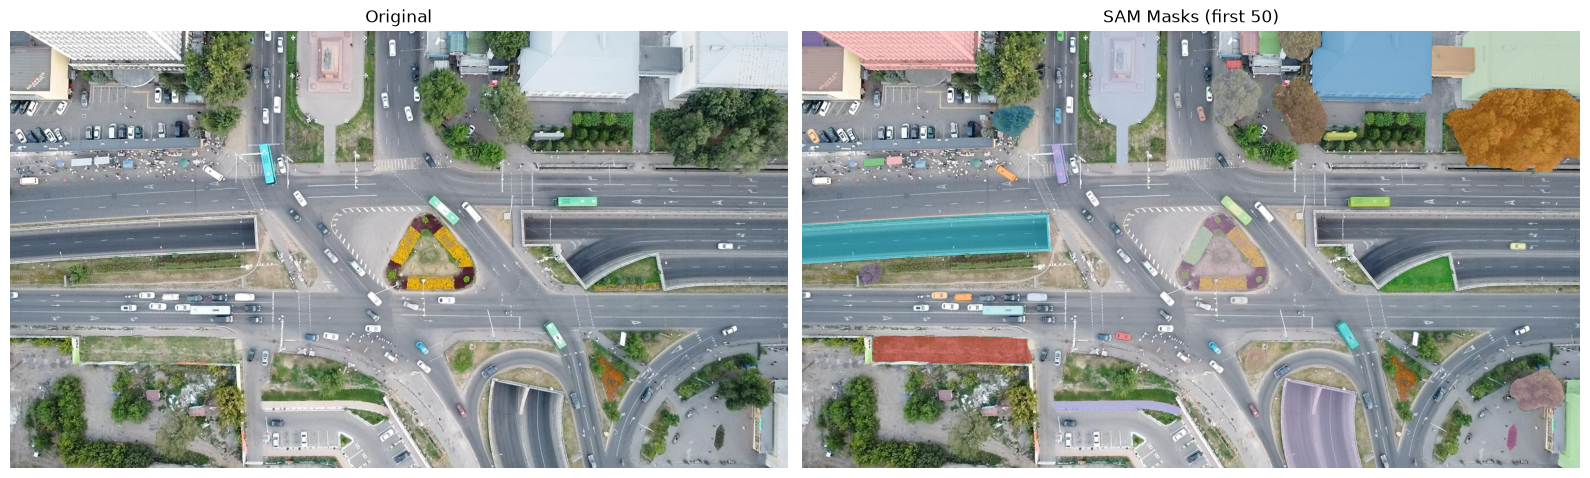

In [8]:
# Visualize SAM masks on a sample image
sample_img_path = train_images[0]
img = cv2.imread(str(sample_img_path))
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
h, w = img.shape[:2]

print(f"Processing: {sample_img_path.name}")
print("Generating masks with SAM 2...")
masks = mask_generator.generate(img_rgb)
print(f"Generated {len(masks)} masks")

# Filter by area
masks = [m for m in masks if m["area"] >= MIN_MASK_AREA]
print(f"After filtering (area >= {MIN_MASK_AREA}): {len(masks)} masks")

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(img_rgb)
axes[0].set_title("Original")
axes[0].axis("off")

overlay = img_rgb.copy()
for i, mask_data in enumerate(masks[:50]):
    mask = mask_data["segmentation"]
    color = plt.cm.tab20(i % 20)
    overlay[mask] = overlay[mask] * 0.5 + np.array(color[:3]) * 255 * 0.5
axes[1].imshow(overlay)
axes[1].set_title("SAM Masks (first 50)")
axes[1].axis("off")
plt.tight_layout()
plt.show()


In [9]:
# Process sampled images and assign classes
import shutil

splits = {
    "train": (train_images, DATA_DIR / "train" / "labels"),
    "valid": (val_images, DATA_DIR / "train" / "labels"),
}

stats = {
    "total_masks": 0,
    "assigned_masks": 0,
    "unassigned_masks": 0,
    "images_processed": 0,
}

for split_name, (images, label_dir) in splits.items():
    out_img_dir = OUTPUT_DIR / split_name / "images"
    out_label_dir = OUTPUT_DIR / split_name / "labels"
    
    print(f"\nProcessing {split_name} split: {len(images)} images")
    
    for img_path in tqdm(images, desc=split_name):
        img = cv2.imread(str(img_path))
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]
        
        # Load GT boxes
        label_path = label_dir / (img_path.stem + ".txt")
        gt_boxes = load_yolo_labels(label_path, h, w)
        
        # Generate masks
        masks = mask_generator.generate(img_rgb)
        masks = [m for m in masks if m["area"] >= MIN_MASK_AREA]
        
        # Write labels
        labels = []
        for mask_data in masks:
            mask = mask_data["segmentation"]
            cls = assign_class_to_mask(mask, gt_boxes, IOU_THRESHOLD)
            
            if cls >= 0:
                stats["assigned_masks"] += 1
                bbox = mask_to_bbox(mask)
                if bbox:
                    labels.append([cls] + bbox)
            else:
                stats["unassigned_masks"] += 1
            
            stats["total_masks"] += 1
        
        # Save image (copy)
        shutil.copy(img_path, out_img_dir / img_path.name)
        
        # Save labels
        label_out_path = out_label_dir / (img_path.stem + ".txt")
        with open(label_out_path, "w") as f:
            for label in labels:
                f.write(" ".join(map(str, label)) + "\n")
        
        stats["images_processed"] += 1

print(f"\n{'='*60}")
print("STATISTICS")
print(f"{'='*60}")
print(f"Images processed: {stats['images_processed']}")
print(f"Total masks generated: {stats['total_masks']}")
print(f"Masks assigned to classes: {stats['assigned_masks']}")
print(f"Masks unassigned (no GT match): {stats['unassigned_masks']}")
print(f"Assignment rate: {stats['assigned_masks'] / stats['total_masks']:.1%}")



Processing train split: 400 images


train: 100%|██████████| 400/400 [6:18:16<00:00, 56.74s/it]     



Processing valid split: 100 images


valid: 100%|██████████| 100/100 [1:04:43<00:00, 38.83s/it]


STATISTICS
Images processed: 500
Total masks generated: 41103
Masks assigned to classes: 7516
Masks unassigned (no GT match): 33587
Assignment rate: 18.3%


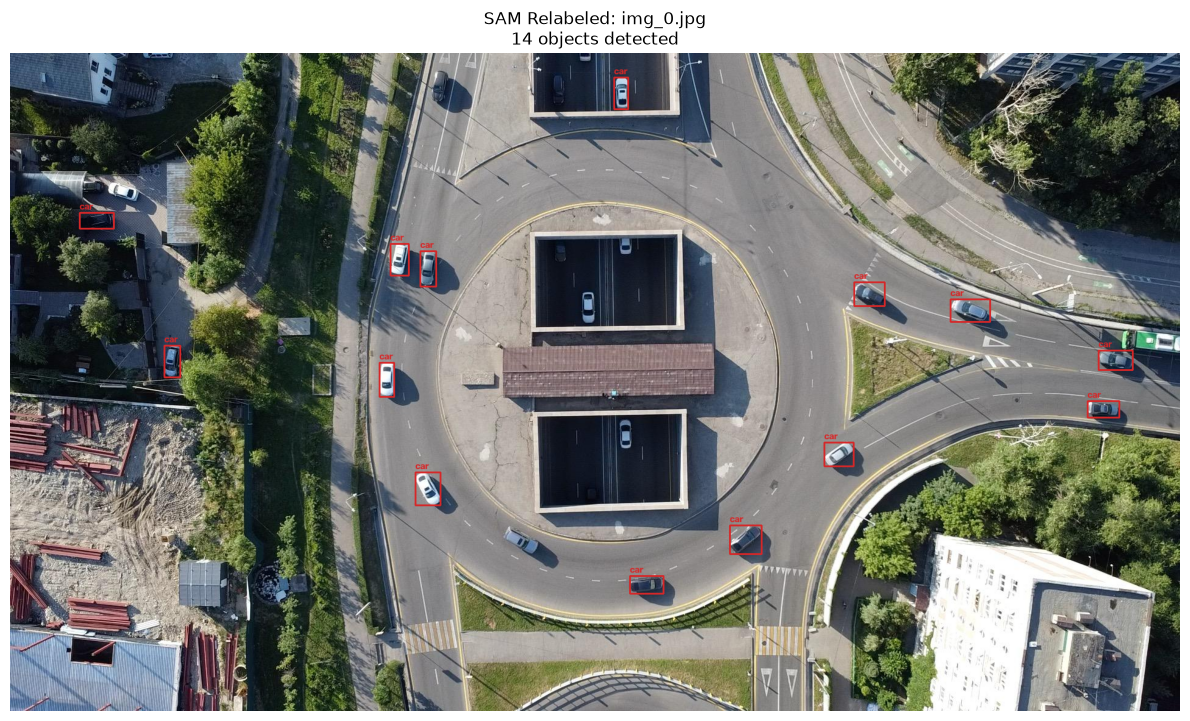

In [10]:
# Visualize relabeled results
sample_img_path = sorted((OUTPUT_DIR / "train" / "images").glob("*.jpg"))[0]
img = cv2.imread(str(sample_img_path))
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
h, w = img.shape[:2]

label_path = OUTPUT_DIR / "train" / "labels" / (sample_img_path.stem + ".txt")
labels = []
with open(label_path) as f:
    for line in f:
        parts = line.strip().split()
        cls = int(parts[0])
        xc, yc, bw, bh = map(float, parts[1:5])
        x1 = (xc - bw / 2) * w
        y1 = (yc - bh / 2) * h
        x2 = (xc + bw / 2) * w
        y2 = (yc + bh / 2) * h
        labels.append({"class": cls, "bbox": [x1, y1, x2, y2]})

from helpers.ntbk_utils import draw_boxes
img_with_boxes = draw_boxes(img_rgb, labels, CLASS_NAMES)

plt.figure(figsize=(12, 8))
plt.imshow(img_with_boxes)
plt.title(f"SAM Relabeled: {sample_img_path.name}\n{len(labels)} objects detected")
plt.axis("off")
plt.tight_layout()
plt.show()


In [11]:
print(f"\n{'='*60}")
print("RELABELING COMPLETE")
print(f"{'='*60}")
print(f"\nNew dataset saved to: {OUTPUT_DIR}")
print(f"Data YAML: {OUTPUT_DIR / 'data.yaml'}")
print(f"\nDataset structure:")
print(f"  Train: {len(train_images)} images (SAM-relabeled)")
print(f"  Val: {len(val_images)} images (SAM-relabeled)")
print(f"  Test: original labels from aerial_images/test/")
print(f"\nNext step: Use this dataset to train a model in notebook 03.")



RELABELING COMPLETE

New dataset saved to: ../data/sam_labels
Data YAML: ../data/sam_labels/data.yaml

Dataset structure:
  Train: 400 images (SAM-relabeled)
  Val: 100 images (SAM-relabeled)
  Test: original labels from aerial_images/test/

Next step: Use this dataset to train a model in notebook 03.
